In [4]:
import sys
sys.path.insert(0,"..")

import networkx as nx
import torch_geometric as tg
import torch
import numpy as np
import bpropy
import matplotlib.pyplot as plt
import time

from bpropy.co.mis import MIS

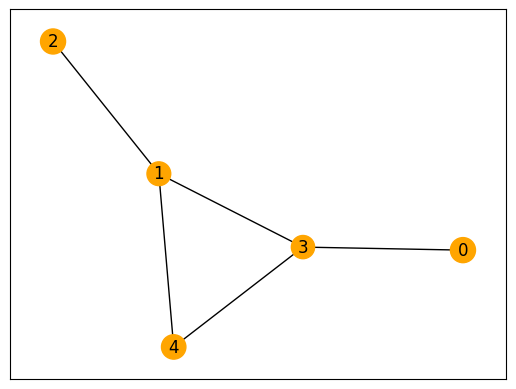

In [16]:
g = nx.generators.random_graphs.erdos_renyi_graph(5, 0.80)
pos = nx.layout.kamada_kawai_layout(g)
# node weights
w = np.random.rand(5)
nx.draw_networkx(g, pos=pos, node_color="orange", node_size=100+300*w)

Factor graph representation of the problem

In [17]:
pb = MIS(g)

In [18]:
for c in pb.constraints():
    print(c.lb, c.ub, c.A)

[-inf] [1.] [[1. 0. 0. 1. 0.]]
[-inf] [1.] [[0. 1. 1. 0. 0.]]
[-inf] [1.] [[0. 1. 0. 1. 0.]]
[-inf] [1.] [[0. 1. 0. 0. 1.]]
[-inf] [1.] [[0. 0. 0. 1. 1.]]


In [19]:
len(list(pb.constraints())) == pb.ne()


True

In [20]:
from bpropy.vc_graph import VCGraph

In [21]:
vcg = VCGraph(pb)

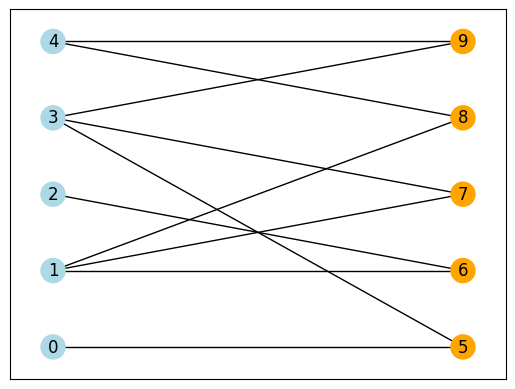

In [25]:
pos = nx.layout.bipartite_layout(vcg, nodes=list(vcg.iter_variables()))
nodecolor = ["lightblue" for _ in range(vcg.nv())] + ["orange" for _ in range(vcg.nc())]
nx.draw_networkx(vcg, pos=pos, node_color=nodecolor)

In [26]:
from bpropy.clique_cover import *

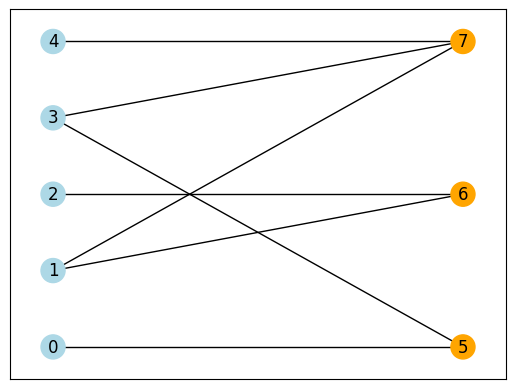

In [30]:
C = clique_cover(pb.g)
pb1 = MIS(g, cliques=C)
vcg = VCGraph(pb1)
pos = nx.layout.bipartite_layout(vcg, nodes=list(vcg.iter_variables()))
nodecolor = ["lightblue" for _ in range(vcg.nv())] + ["orange" for _ in range(vcg.nc())]
nx.draw_networkx(vcg, pos=pos, node_color=nodecolor)

In [31]:
C

[[0, 3], [1, 2], [1, 3, 4]]